# Transaction Anomaly Detection

## Overview

This project uses machine learning to identify potentially anomalous transactions.

The project demonstrates how the Isolation Forest algorithm can be used for unsupervised anomaly detection on transaction data.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
# Create sample transaction data

np.random.seed(42)

n_transactions = 1000

data = {
    "transaction_amount": np.random.normal(500, 100, n_transactions),
    "transaction_hour": np.random.randint(0, 24, n_transactions),
    "transaction_frequency": np.random.poisson(3, n_transactions)
}

transactions = pd.DataFrame(data)

transactions.head()

,transaction_amount,transaction_hour,transaction_frequency
0,549.671415,22,1
1,486.173570,11,8
2,564.768854,16,4
3,652.302986,7,2
4,476.584663,10,0


In [20]:
# Add some anomalous transactions

anomaly_indices = np.random.choice(
    transactions.index,
    size=20,
    replace=False
)

transactions["transaction_amount"] = transactions["transaction_amount"].astype(float)
transactions["transaction_hour"] = transactions["transaction_hour"].astype(int)
transactions["transaction_frequency"] = transactions["transaction_frequency"].astype(int)

transactions.loc[anomaly_indices, "transaction_amount"] = np.random.uniform(
    2000, 5000, 20
)

transactions.loc[anomaly_indices, "transaction_hour"] = np.random.choice(
    [0, 1, 2, 3, 4],
    size=20
)

transactions.loc[anomaly_indices, "transaction_frequency"] = np.random.randint(
    10, 20, 20
)

transactions.head()

,transaction_amount,transaction_hour,transaction_frequency
0,3622.481192,1,11
1,486.173570,11,8
2,564.768854,16,4
3,652.302986,7,2
4,476.584663,10,0


In [21]:
# Train the Isolation Forest model

features = [
    "transaction_amount",
    "transaction_hour",
    "transaction_frequency"
]

model = IsolationForest(
    contamination=0.02,
    random_state=42
)

model.fit(transactions[features])

transactions["anomaly"] = model.predict(transactions[features])

transactions.head()

,transaction_amount,transaction_hour,transaction_frequency,anomaly
0,3622.481192,1,11,1
1,486.173570,11,8,1
2,564.768854,16,4,1
3,652.302986,7,2,1
4,476.584663,10,0,1


In [22]:
# Count detected anomalies

anomaly_count = (transactions["anomaly"] == -1).sum()
normal_count = (transactions["anomaly"] == 1).sum()

print(f"Normal transactions: {normal_count}")
print(f"Anomalous transactions: {anomaly_count}")

Normal transactions: 980
Anomalous transactions: 20


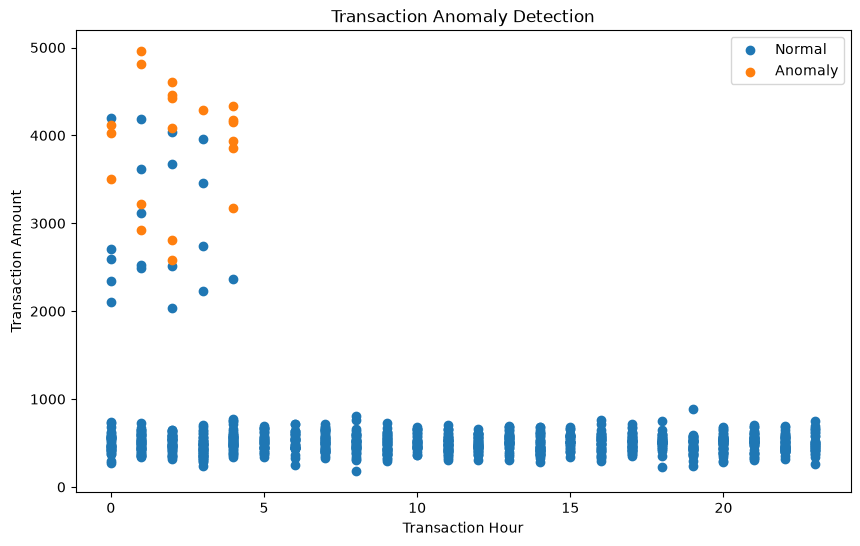

In [23]:
# Visualize normal and anomalous transactions

normal = transactions[transactions["anomaly"] == 1]
anomalies = transactions[transactions["anomaly"] == -1]

plt.figure(figsize=(10, 6))

plt.scatter(
    normal["transaction_hour"],
    normal["transaction_amount"],
    label="Normal"
)

plt.scatter(
    anomalies["transaction_hour"],
    anomalies["transaction_amount"],
    label="Anomaly"
)

plt.xlabel("Transaction Hour")
plt.ylabel("Transaction Amount")
plt.title("Transaction Anomaly Detection")
plt.legend()
plt.show()

In [24]:
# Display detected anomalous transactions

anomalous_transactions = transactions[
    transactions["anomaly"] == -1
].sort_values(
    by="transaction_amount",
    ascending=False
)

anomalous_transactions.head(10)

,transaction_amount,transaction_hour,transaction_frequency,anomaly
480,4954.744298,1,11,-1
49,4809.710654,1,13,-1
284,4608.623507,2,15,-1
460,4455.081924,2,19,-1
345,4423.494355,2,15,-1
196,4331.997542,4,15,-1
463,4292.286760,3,18,-1
416,4176.404505,4,17,-1
343,4150.155757,4,14,-1
968,4117.971209,0,12,-1


## Results

The Isolation Forest model was used to identify potentially anomalous transactions based on:

- Transaction amount
- Transaction hour
- Transaction frequency

The model assigns:
- `1` to transactions considered normal
- `-1` to transactions considered anomalous

The detected anomalies can be reviewed using the table and visualization above.